# Introduction to Deep Learning — Full Course for Google Colab

## Theory → Neural Networks from Scratch → Keras/TensorFlow → MLP → CNN → Evaluation → Exercises

This notebook is designed as a hands-on introduction to **Deep Learning**.

### Learning objectives

By the end of the course, you should be able to:

1. Explain what a neural network is and how it learns.
2. Understand neurons, layers, weights, biases and activation functions.
3. Explain forward propagation, loss and backpropagation.
4. Understand gradient descent and common optimizers.
5. Build a neural network with `tf.keras`.
6. Train an MLP for image classification.
7. Understand why CNNs are useful for images.
8. Build and evaluate a CNN.
9. Recognize overfitting and apply dropout / early stopping.
10. Interpret training curves and a confusion matrix.
11. Save a trained model and use it for inference.

> **Platform:** Google Colab  
> **Main framework:** TensorFlow / Keras  
> **Dataset:** MNIST handwritten digits


## Course roadmap

| Part | Topic | Main idea |
|---|---|---|
| 0 | Colab setup | Prepare the environment |
| 1 | Deep Learning basics | What problem does DL solve? |
| 2 | The neuron | Weighted sum + activation |
| 3 | Activation functions | Add non-linearity |
| 4 | Forward propagation | Compute predictions |
| 5 | Loss functions | Measure prediction error |
| 6 | Gradient descent | Improve parameters |
| 7 | Backpropagation | Efficiently compute gradients |
| 8 | Neural network architecture | Stack layers |
| 9 | TensorFlow/Keras | Build a real model |
| 10 | MNIST + MLP | First complete project |
| 11 | Overfitting | Validation, dropout, early stopping |
| 12 | CNN | Deep learning for images |
| 13 | CNN project | Complete image classifier |
| 14 | Evaluation | Confusion matrix and error analysis |
| 15 | Exercises | Practice and mini-projects |
| 16 | Final challenge | Build your own classifier |

**Suggested use:** run cells from top to bottom and modify the parameters marked with `# TRY:`.


# 0. Colab setup

Google Colab provides a cloud Python environment. For this course we will use:

- NumPy for numerical operations
- Pandas for simple data inspection
- Matplotlib for visualization
- Scikit-learn for evaluation utilities
- TensorFlow/Keras for deep learning


In [ ]:
# Import the main libraries used throughout the course.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TensorFlow provides the deep-learning engine used in this notebook.
import tensorflow as tf

# Keras is the high-level API included with TensorFlow.
from tensorflow import keras
from tensorflow.keras import layers

# Scikit-learn gives us useful evaluation tools.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Make NumPy output easier to read.
np.set_printoptions(precision=4, suppress=True)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)


TensorFlow version: 2.21.0
NumPy version: 2.1.3


## 0.1 Check whether a GPU is available

A GPU is not required for the small examples in this course, but it becomes useful for CNNs and larger datasets.

In Colab:

**Runtime → Change runtime type → T4 GPU** (or another available accelerator).


In [ ]:
# Ask TensorFlow which physical devices are available.
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU available:", gpus)
else:
    print("No GPU detected. The notebook can still run on CPU.")


No GPU detected. The notebook can still run on CPU.


# 1. What is Deep Learning?

Deep Learning is a family of machine-learning methods based on **neural networks with multiple layers**.

A traditional ML pipeline often depends on manually designed features:

**raw data → engineered features → classifier**

Deep learning aims to learn useful representations directly:

**raw data → neural network → prediction**

For images, the model can learn progressively richer representations:

**pixels → edges → textures/shapes → objects/classes**

### Key idea

The network does not receive a rule such as:

> "A 7 contains a diagonal line."

Instead, it learns numerical parameters from examples.


## 1.1 Artificial neuron

A simple neuron receives inputs:

$$
x_1, x_2, ..., x_n
$$

and computes a weighted sum:

$$
z = w_1x_1 + w_2x_2 + ... + w_nx_n + b
$$

or more compactly:

$$
z = w^T x + b
$$

Then an activation function produces the output:

$$
a = \phi(z)
$$

### Interpretation

- `x` = input
- `w` = learnable weights
- `b` = learnable bias
- `z` = pre-activation / weighted sum
- `φ` = activation function
- `a` = neuron output


In [ ]:
# A tiny neuron implemented directly with NumPy.
# This is for intuition: no TensorFlow is involved yet.

x = np.array([2.0, 1.0])       # Two input features.
w = np.array([0.6, -0.3])     # Two learnable weights.
b = 0.2                        # One learnable bias.

# Compute the weighted sum z = w^T x + b.
z = np.dot(w, x) + b

# Use a simple ReLU activation: max(0, z).
a = max(0.0, z)

print("Weighted sum z =", z)
print("Neuron output a =", a)


Weighted sum z = 1.0999999999999999
Neuron output a = 1.0999999999999999


# 2. Activation functions

Without nonlinear activation functions, stacking many linear layers would still produce a linear transformation.

Activation functions introduce **non-linearity**, allowing a neural network to learn complex patterns.

Common functions:

- **Sigmoid:** useful for binary output probabilities
- **Tanh:** centered around zero
- **ReLU:** most common hidden-layer activation in modern basic networks
- **Softmax:** converts multiclass output scores into probabilities


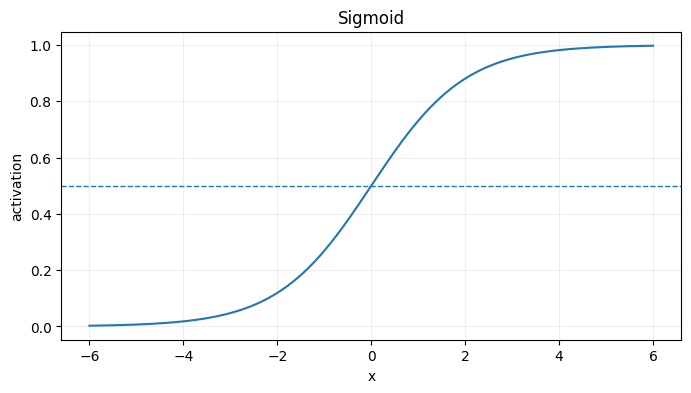

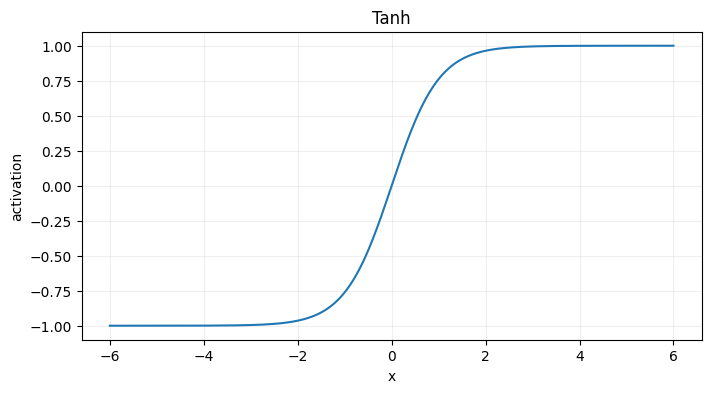

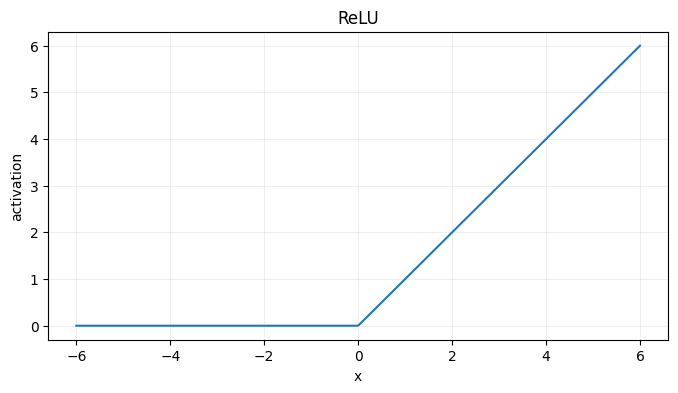

In [ ]:
# Define several common activation functions with NumPy.

def sigmoid(x):
    # Sigmoid maps any real number to the interval (0, 1).
    return 1 / (1 + np.exp(-x))

def tanh(x):
    # Hyperbolic tangent maps values to (-1, 1).
    return np.tanh(x)

def relu(x):
    # ReLU keeps positive values and replaces negative values by zero.
    return np.maximum(0, x)

x = np.linspace(-6, 6, 400)

# Draw each activation function separately for easy comparison.
plt.figure(figsize=(8, 4))
plt.plot(x, sigmoid(x))
plt.axhline(0.5, linestyle="--", linewidth=1)
plt.title("Sigmoid")
plt.xlabel("x")
plt.ylabel("activation")
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(x, tanh(x))
plt.title("Tanh")
plt.xlabel("x")
plt.ylabel("activation")
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(x, relu(x))
plt.title("ReLU")
plt.xlabel("x")
plt.ylabel("activation")
plt.grid(alpha=0.2)
plt.show()


## 2.1 Exercise — Activation functions

Complete the code:

1. Evaluate sigmoid at `-2`, `0`, and `2`.
2. Evaluate ReLU at `[-3, -1, 0, 2, 5]`.
3. Explain in one sentence why ReLU outputs zero for negative inputs.


In [ ]:
# EXERCISE STARTER
values = np.array([-2.0, 0.0, 2.0])

# TODO 1: Compute the sigmoid of "values".
sigmoid_values = None

relu_inputs = np.array([-3.0, -1.0, 0.0, 2.0, 5.0])

# TODO 2: Compute ReLU of "relu_inputs".
relu_values = None

print("Sigmoid:", sigmoid_values)
print("ReLU:", relu_values)

# TRY: Replace the inputs by your own values and observe the result.


Sigmoid: None
ReLU: None


In [ ]:
# EXERCISE SOLUTION
values = np.array([-2.0, 0.0, 2.0])

# Apply the sigmoid function element by element.
sigmoid_values = sigmoid(values)

relu_inputs = np.array([-3.0, -1.0, 0.0, 2.0, 5.0])

# Apply ReLU element by element.
relu_values = relu(relu_inputs)

print("Sigmoid:", sigmoid_values)
print("ReLU:", relu_values)


Sigmoid: [0.1192 0.5    0.8808]
ReLU: [0. 0. 0. 2. 5.]


# 3. Forward propagation

Consider a small network:

**2 inputs → 3 hidden neurons → 2 output neurons**

Forward propagation means computing the activations from left to right.

For one layer:

$$
z^{(l)} = W^{(l)}a^{(l-1)} + b^{(l)}
$$

$$
a^{(l)} = \phi(z^{(l)})
$$

The final layer produces scores that can be converted into probabilities.


In [ ]:
# Softmax converts output scores (logits) into a probability distribution.
def softmax(logits):
    # Subtract the maximum for numerical stability.
    shifted = logits - np.max(logits)
    exp_values = np.exp(shifted)
    return exp_values / np.sum(exp_values)

# One sample with two input features.
x = np.array([1.2, -0.7])

# Hidden-layer parameters.
W1 = np.array([
    [0.5, -0.2],
    [0.3,  0.8],
    [-0.4, 0.1]
])
b1 = np.array([0.1, 0.0, -0.2])

# Output-layer parameters.
W2 = np.array([
    [0.7, -0.3, 0.5],
    [-0.2, 0.6, -0.4]
])
b2 = np.array([0.05, -0.05])

# Forward pass through the hidden layer.
z1 = W1 @ x + b1
a1 = relu(z1)

# Forward pass through the output layer.
z2 = W2 @ a1 + b2
probabilities = softmax(z2)

print("Hidden pre-activation z1:", z1)
print("Hidden activation a1:", a1)
print("Output logits z2:", z2)
print("Output probabilities:", probabilities)
print("Probability sum:", probabilities.sum())


Hidden pre-activation z1: [ 0.84 -0.2  -0.75]
Hidden activation a1: [0.84 0.   0.  ]
Output logits z2: [ 0.638 -0.218]
Output probabilities: [0.7018 0.2982]
Probability sum: 1.0


# 4. Loss functions

A neural network needs a numerical measure of how wrong its prediction is.

That measure is the **loss function**.

For multiclass classification with one correct class, categorical cross-entropy is:

$$
L = -\log(p_{true})
$$

where `p_true` is the probability assigned to the correct class.

### Intuition

- Correct class probability near **1** → small loss.
- Correct class probability near **0** → large loss.

During training, the network tries to minimize the average loss.


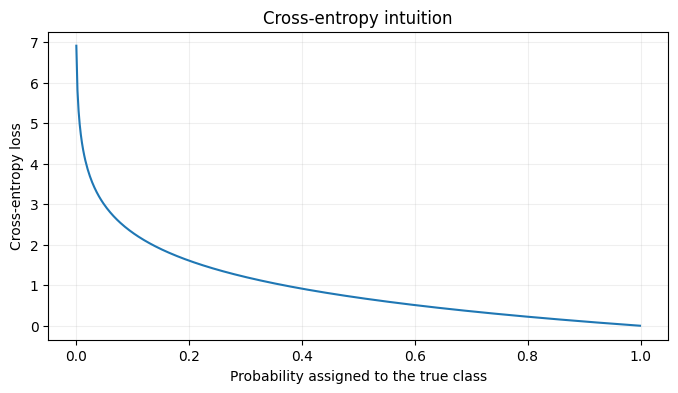

In [ ]:
# Demonstrate how cross-entropy changes with the probability assigned to the true class.
p_true = np.linspace(0.001, 0.999, 500)

# For one-hot multiclass classification, loss for the true class is -log(p_true).
loss = -np.log(p_true)

plt.figure(figsize=(8, 4))
plt.plot(p_true, loss)
plt.xlabel("Probability assigned to the true class")
plt.ylabel("Cross-entropy loss")
plt.title("Cross-entropy intuition")
plt.grid(alpha=0.2)
plt.show()


## 4.1 Example — manual cross-entropy

Suppose the correct class is class `2`.

The model outputs:

```text
class 0 → 0.10
class 1 → 0.20
class 2 → 0.70   ← correct class
```

The loss is:

$$
-\log(0.70)
$$

This is much smaller than the loss obtained if the model assigns only `0.05` to the correct class.


In [ ]:
# Example: calculate cross-entropy for two predictions.

p_good = 0.70
p_bad = 0.05

loss_good = -np.log(p_good)
loss_bad = -np.log(p_bad)

print("Loss when p_true = 0.70:", loss_good)
print("Loss when p_true = 0.05:", loss_bad)


Loss when p_true = 0.70: 0.35667494393873245
Loss when p_true = 0.05: 2.995732273553991


# 5. Gradient descent

The model parameters are:

$$
\theta = \{W, b\}
$$

Training attempts to minimize the loss:

$$
\theta^* = \arg\min_\theta L(\theta)
$$

A basic gradient-descent update is:

$$
\theta_{new} = \theta_{old} - \eta \frac{\partial L}{\partial \theta}
$$

where `η` is the learning rate.

Think of the loss as a landscape. The gradient tells us the direction of steepest increase, so we move in the opposite direction.


Final x: 3.000182807922003


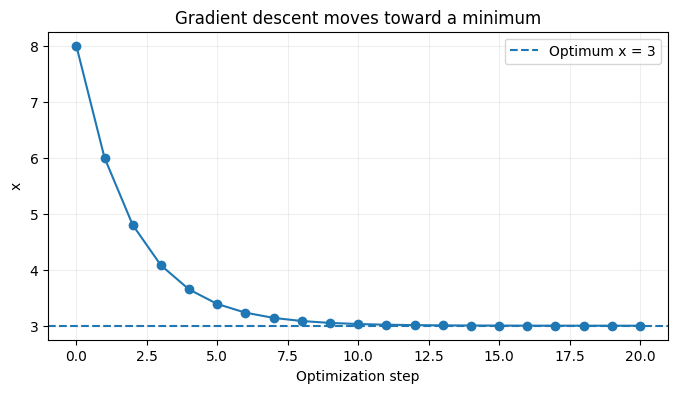

In [ ]:
# A simple 1D gradient-descent demonstration.
# We want to minimize f(x) = (x - 3)^2.

x = 8.0
learning_rate = 0.2
history = [x]

for step in range(20):
    # Derivative of (x - 3)^2 is 2 * (x - 3).
    gradient = 2 * (x - 3)

    # Move in the opposite direction of the gradient.
    x = x - learning_rate * gradient

    # Save the position to visualize the optimization path.
    history.append(x)

print("Final x:", x)

plt.figure(figsize=(8, 4))
plt.plot(history, marker="o")
plt.axhline(3, linestyle="--", label="Optimum x = 3")
plt.xlabel("Optimization step")
plt.ylabel("x")
plt.title("Gradient descent moves toward a minimum")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


## 5.1 Learning rate experiment

The learning rate controls the step size.

Try these values:

- `0.001` → very slow
- `0.1` → reasonable for this toy problem
- `1.0` → much more aggressive
- a very large value → can overshoot or become unstable

The best learning rate depends on the problem and optimizer.


Final value: 3.0576460752303425


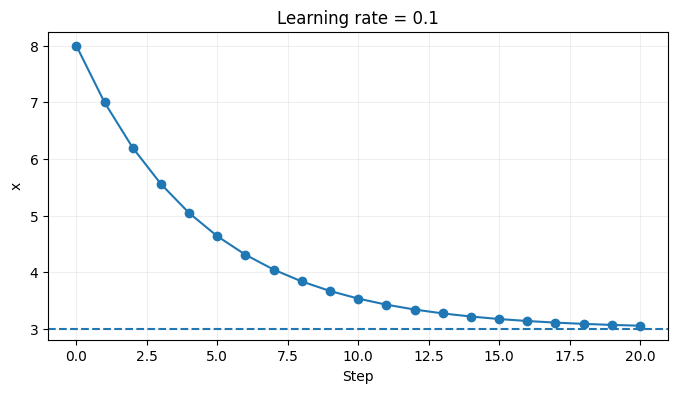

In [ ]:
# EXERCISE
# Change this value and observe the trajectory.
learning_rate = 0.1

x = 8.0
history = [x]

for step in range(20):
    # Gradient of the toy function.
    gradient = 2 * (x - 3)

    # Gradient-descent update.
    x = x - learning_rate * gradient
    history.append(x)

print("Final value:", x)

plt.figure(figsize=(8, 4))
plt.plot(history, marker="o")
plt.axhline(3, linestyle="--")
plt.title(f"Learning rate = {learning_rate}")
plt.xlabel("Step")
plt.ylabel("x")
plt.grid(alpha=0.2)
plt.show()


# 6. Backpropagation

For a network with many layers, changing one weight affects later activations and therefore the final loss.

**Backpropagation** uses the chain rule from calculus to efficiently compute how the loss changes with respect to each parameter.

Conceptually:

**forward pass:** inputs → predictions → loss

**backward pass:** loss → gradients → parameter updates

Then the process repeats for many batches and epochs.

You do not normally implement all derivatives manually in Keras. TensorFlow's automatic differentiation system computes them for you.


In [ ]:
# Tiny demonstration of TensorFlow automatic differentiation.

# Create a trainable scalar parameter.
w = tf.Variable(4.0)

with tf.GradientTape() as tape:
    # Define a simple loss: (w - 1)^2.
    loss = (w - 1.0) ** 2

# Ask TensorFlow for d(loss) / d(w).
gradient = tape.gradient(loss, w)

print("w =", w.numpy())
print("loss =", loss.numpy())
print("gradient =", gradient.numpy())


w = 4.0
loss = 9.0
gradient = 6.0


# 7. Neural-network architectures

A typical feed-forward classifier can look like:

```text
Input features
      ↓
Dense layer + ReLU
      ↓
Dense layer + ReLU
      ↓
Dense layer + Softmax
      ↓
Class probabilities
```

### Important architectural ideas

**Width** = number of neurons in a layer.

**Depth** = number of learnable layers.

**Parameters** = weights + biases learned from data.

More layers are not automatically better. Architecture should match the problem and dataset.


## 7.1 Parameter-count example

For a dense layer with:

- 784 inputs
- 128 neurons

the number of weights is:

$$
784 \times 128
$$

and there are 128 bias values.


In [ ]:
# Calculate the parameter count of a dense layer manually.
inputs = 784
neurons = 128

weights = inputs * neurons
biases = neurons
total_parameters = weights + biases

print("Weights:", weights)
print("Biases:", biases)
print("Total trainable parameters:", total_parameters)


Weights: 100352
Biases: 128
Total trainable parameters: 100480


# 8. Load MNIST

MNIST contains handwritten digits from `0` to `9`.

Each image is:

$$
28 \times 28
$$

with one grayscale channel.

The task is **10-class classification**.

We will first solve the problem with a Multilayer Perceptron (MLP), then with a Convolutional Neural Network (CNN).


In [ ]:
# Load the MNIST dataset directly through Keras.
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


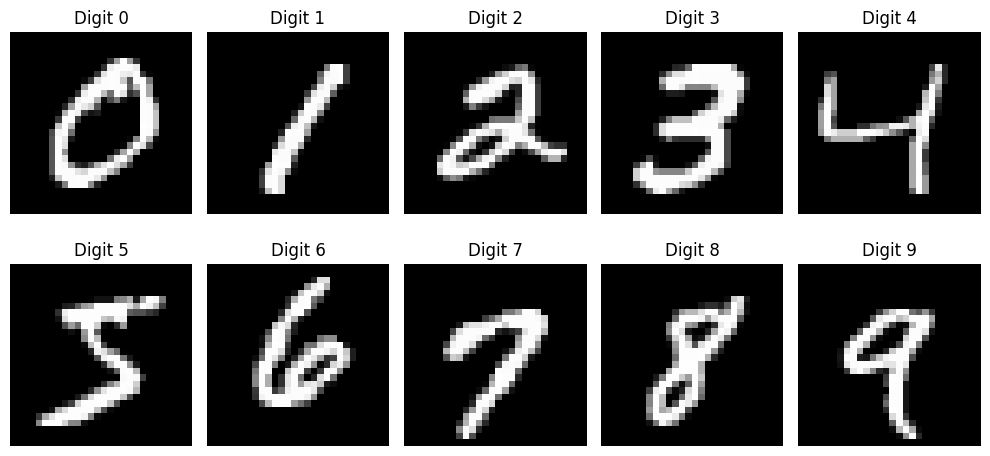

In [ ]:
# Display one example from each digit class.
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for digit in range(10):
    # Find the first training example belonging to this digit.
    idx = np.where(y_train == digit)[0][0]

    ax = axes.ravel()[digit]
    ax.imshow(X_train[idx], cmap="gray")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")

plt.tight_layout()
plt.show()


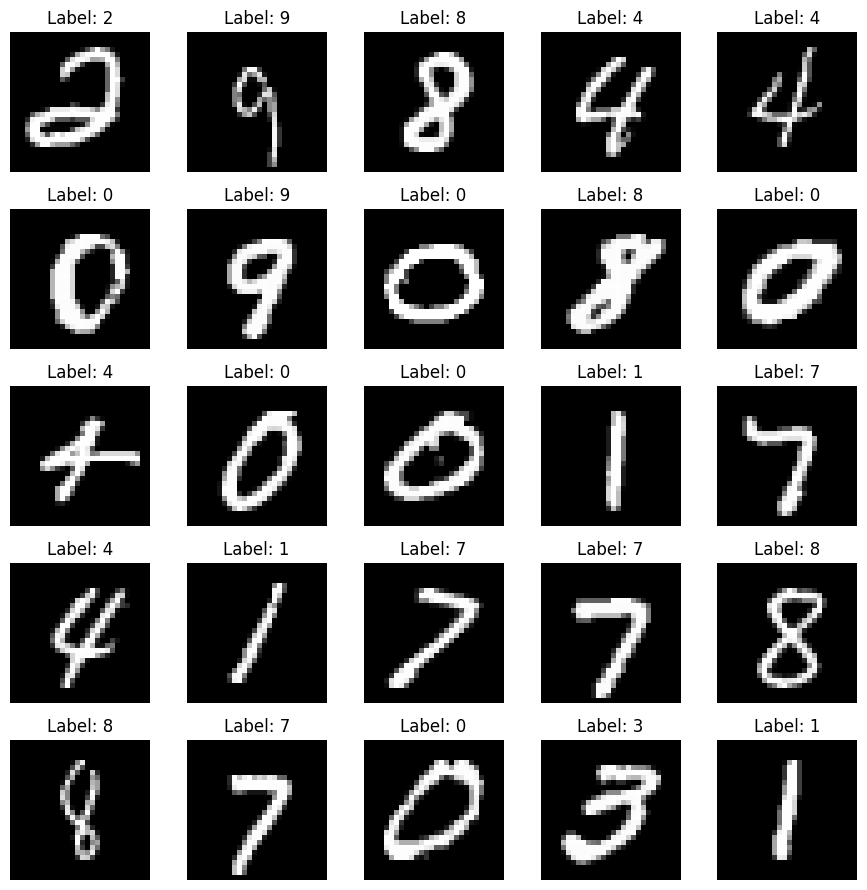

In [ ]:
# Plot a small gallery to see variation between handwritten digits.
rng = np.random.default_rng(42)
indices = rng.choice(len(X_train), size=25, replace=False)

fig, axes = plt.subplots(5, 5, figsize=(9, 9))

for ax, idx in zip(axes.ravel(), indices):
    ax.imshow(X_train[idx], cmap="gray")
    ax.set_title(f"Label: {y_train[idx]}")
    ax.axis("off")

plt.tight_layout()
plt.show()


# 9. Data preparation

Pixel values are originally integers from `0` to `255`.

A common preprocessing step is:

$$
x_{scaled} = x / 255
$$

so the values lie approximately in `[0, 1]`.

For an MLP, we will also flatten each image:

$$
28 \times 28 = 784
$$

For a CNN, we **will not flatten the image** because convolution layers use the spatial structure.


In [ ]:
# Convert pixel values from [0, 255] to [0, 1].
X_train_norm = X_train.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0

print("Minimum pixel value:", X_train_norm.min())
print("Maximum pixel value:", X_train_norm.max())

# Flatten the images for the MLP.
X_train_mlp = X_train_norm.reshape(-1, 28 * 28)
X_test_mlp = X_test_norm.reshape(-1, 28 * 28)

print("MLP input shape:", X_train_mlp.shape)


Minimum pixel value: 0.0
Maximum pixel value: 1.0
MLP input shape: (60000, 784)


## 9.1 Exercise — inspect the data

Before training a model, inspect:

1. image shape,
2. number of classes,
3. class distribution,
4. minimum and maximum pixel values.


In [ ]:
# EXERCISE
print("Image shape:", X_train.shape)

# TODO: Find the number of unique classes.
num_classes = None

# TODO: Count the number of training examples in each class.
class_counts = None

# TODO: Print the minimum and maximum values.
min_pixel = None
max_pixel = None

print("Number of classes:", num_classes)
print("Class counts:", class_counts)
print("Min / max pixel:", min_pixel, max_pixel)


Image shape: (60000, 28, 28)
Number of classes: None
Class counts: None
Min / max pixel: None None


# 10. Build the first Deep Learning model — MLP

Our first Keras network:

```text
784 inputs
   ↓
Dense(128) + ReLU
   ↓
Dropout(0.2)
   ↓
Dense(64) + ReLU
   ↓
Dense(10) + Softmax
```

This is a **Multilayer Perceptron**.

The final layer has 10 outputs, one for each digit.

### Why Softmax?

For multiclass classification we want a probability distribution whose values add up to 1.


In [ ]:
# Build a simple MLP using Keras Sequential API.
mlp = keras.Sequential([
    # The first Dense layer receives 784 flattened pixel values.
    layers.Input(shape=(784,)),

    # Learn nonlinear combinations of pixels.
    layers.Dense(128, activation="relu"),

    # Randomly deactivate 20% of neurons during training to reduce overfitting.
    layers.Dropout(0.20),

    # A second hidden representation.
    layers.Dense(64, activation="relu"),

    # Ten outputs correspond to digits 0-9.
    # Softmax turns the outputs into class probabilities.
    layers.Dense(10, activation="softmax")
])

# Display the architecture.
mlp.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

# 11. Compile the model

Compilation specifies:

- **optimizer:** how parameters are updated,
- **loss:** what the model minimizes,
- **metrics:** what we monitor.

For integer labels `0...9`, `sparse_categorical_crossentropy` is convenient because we do not need to manually one-hot encode the labels.


In [ ]:
# Configure the learning process.
mlp.compile(
    # Adam is a popular adaptive-gradient optimizer.
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),

    # Suitable for integer labels in a multiclass problem.
    loss="sparse_categorical_crossentropy",

    # Accuracy is easy to interpret for MNIST.
    metrics=["accuracy"]
)

print("Model compiled successfully.")


Model compiled successfully.


# 12. Train the MLP

An **epoch** is one complete pass through the training data.

A **batch** is a subset of the training data processed in one update.

We will use a validation split to monitor generalization during training.

> For a classroom notebook, the number of epochs is kept moderate so the code remains practical in Colab.


In [ ]:
# Train the MLP.
history = mlp.fit(
    X_train_mlp,
    y_train,
    epochs=8,
    batch_size=128,
    validation_split=0.10,
    verbose=1
)


Epoch 1/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8790 - loss: 0.4098 - val_accuracy: 0.9608 - val_loss: 0.1396
Epoch 2/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9477 - loss: 0.1735 - val_accuracy: 0.9712 - val_loss: 0.1009
Epoch 3/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9610 - loss: 0.1300 - val_accuracy: 0.9723 - val_loss: 0.0902
Epoch 4/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9679 - loss: 0.1036 - val_accuracy: 0.9760 - val_loss: 0.0767
Epoch 5/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9716 - loss: 0.0888 - val_accuracy: 0.9782 - val_loss: 0.0741
Epoch 6/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9746 - loss: 0.0789 - val_accuracy: 0.9790 - val_loss: 0.0699
Epoch 7/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9780 - loss: 0.0683 - val_accuracy: 0.9818 - val_loss: 0.0696
Epoch 8/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9815 - loss: 0.0600 - val_accuracy: 0.9788 - 

## 12.1 Training curves

Two curves are particularly important:

- training loss vs validation loss
- training accuracy vs validation accuracy

Typical patterns:

**Good fit:** both training and validation improve and remain reasonably close.

**Overfitting:** training continues to improve while validation stops improving or becomes worse.

**Underfitting:** both remain poor.


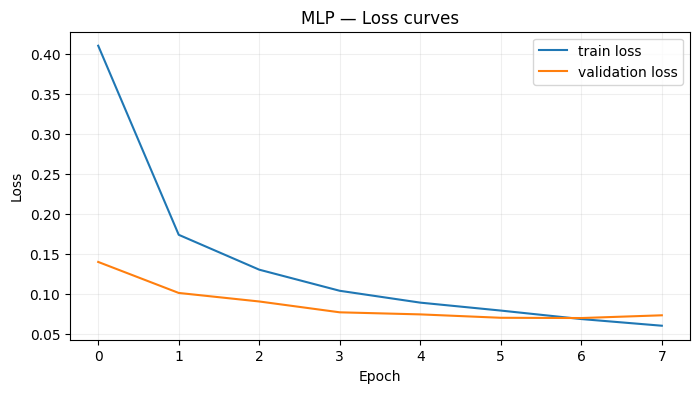

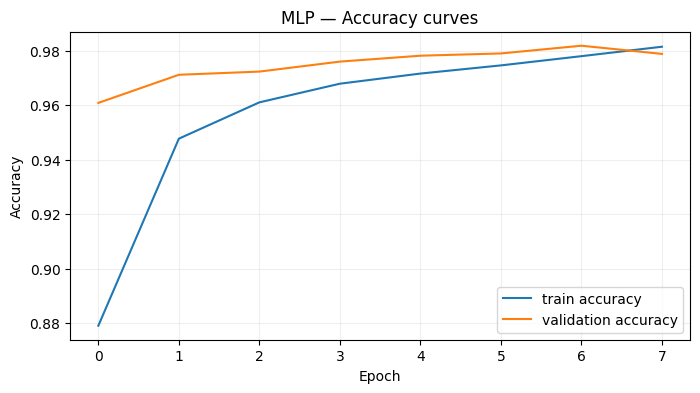

In [ ]:
# Convert the Keras History object into a DataFrame for easy inspection.
history_df = pd.DataFrame(history.history)

# Plot training and validation loss.
plt.figure(figsize=(8, 4))
plt.plot(history_df["loss"], label="train loss")
plt.plot(history_df["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP — Loss curves")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Plot training and validation accuracy.
plt.figure(figsize=(8, 4))
plt.plot(history_df["accuracy"], label="train accuracy")
plt.plot(history_df["val_accuracy"], label="validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP — Accuracy curves")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# 13. Evaluate on unseen test data

The test set should be used for the final evaluation after the model and training strategy have been selected.

Accuracy is:

$$
Accuracy = \frac{\text{correct predictions}}{\text{all predictions}}
$$

For balanced MNIST, accuracy is a useful first metric.


In [ ]:
# Evaluate the model on data it has never seen during training.
test_loss, test_accuracy = mlp.evaluate(X_test_mlp, y_test, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")


Test loss: 0.0743
Test accuracy: 0.9765


## 13.1 Predict one image

A useful deep-learning workflow should make it easy to pass one image through the model and inspect the result.

The model returns 10 probabilities:

```text
P(0), P(1), ..., P(9)
```

The predicted class is the index with the largest probability.


True digit: 6
Predicted digit: 6


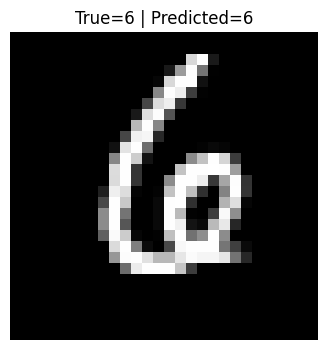

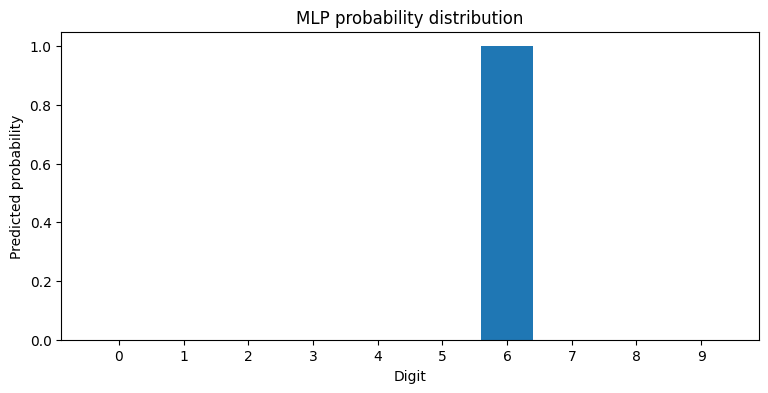

In [ ]:
# Select one test image.
sample_index = 123
sample_image = X_test[sample_index]

# Prepare it exactly as the MLP expects: normalize + flatten + add batch dimension.
sample_input = sample_image.astype("float32") / 255.0
sample_input = sample_input.reshape(1, 784)

# Ask the trained model for class probabilities.
sample_probs = mlp.predict(sample_input, verbose=0)[0]

# Select the class with maximum probability.
predicted_digit = int(np.argmax(sample_probs))

print("True digit:", int(y_test[sample_index]))
print("Predicted digit:", predicted_digit)

# Show the image.
plt.figure(figsize=(4, 4))
plt.imshow(sample_image, cmap="gray")
plt.title(f"True={y_test[sample_index]} | Predicted={predicted_digit}")
plt.axis("off")
plt.show()

# Show the probability distribution.
plt.figure(figsize=(9, 4))
plt.bar(np.arange(10), sample_probs)
plt.xticks(np.arange(10))
plt.xlabel("Digit")
plt.ylabel("Predicted probability")
plt.title("MLP probability distribution")
plt.show()


# 14. Confusion matrix and error analysis

A confusion matrix shows which classes are predicted correctly and which classes are confused.

For a good classifier, most counts should be concentrated on the diagonal.


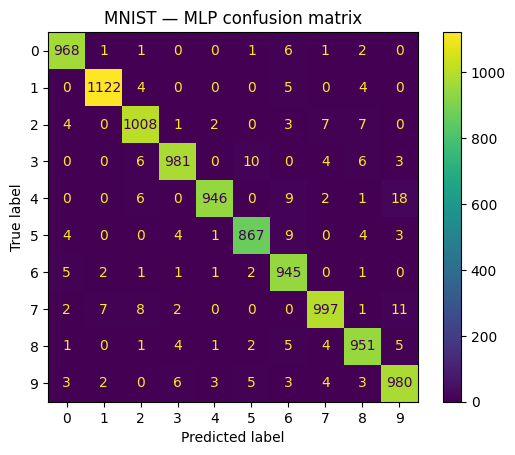

              precision    recall  f1-score   support

           0     0.9807    0.9878    0.9842       980
           1     0.9894    0.9885    0.9890      1135
           2     0.9739    0.9767    0.9753      1032
           3     0.9820    0.9713    0.9766      1010
           4     0.9916    0.9633    0.9773       982
           5     0.9775    0.9720    0.9747       892
           6     0.9594    0.9864    0.9727       958
           7     0.9784    0.9698    0.9741      1028
           8     0.9704    0.9764    0.9734       974
           9     0.9608    0.9713    0.9660      1009

    accuracy                         0.9765     10000
   macro avg     0.9764    0.9764    0.9763     10000
weighted avg     0.9766    0.9765    0.9765     10000



In [ ]:
# Predict all test samples.
y_prob = mlp.predict(X_test_mlp, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Display the confusion matrix.
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))
disp.plot(values_format="d", xticks_rotation=0)
plt.title("MNIST — MLP confusion matrix")
plt.show()

# Print precision, recall and F1-score for every digit.
print(classification_report(y_test, y_pred, digits=4))


## 14.1 Exercise — inspect errors

Find several incorrectly classified images.

Ask:

- Which digit is the true class?
- Which digit did the model predict?
- Does the handwriting look ambiguous?
- Are there repeated confusion patterns?


In [ ]:
# EXERCISE
# Find the indexes where the prediction is wrong.
wrong_indices = np.where(y_pred != y_test)[0]

print("Number of errors:", len(wrong_indices))

# TODO: Display the first 20 incorrect predictions.
# Hint: create a 4x5 grid and use imshow().


Number of errors: 235


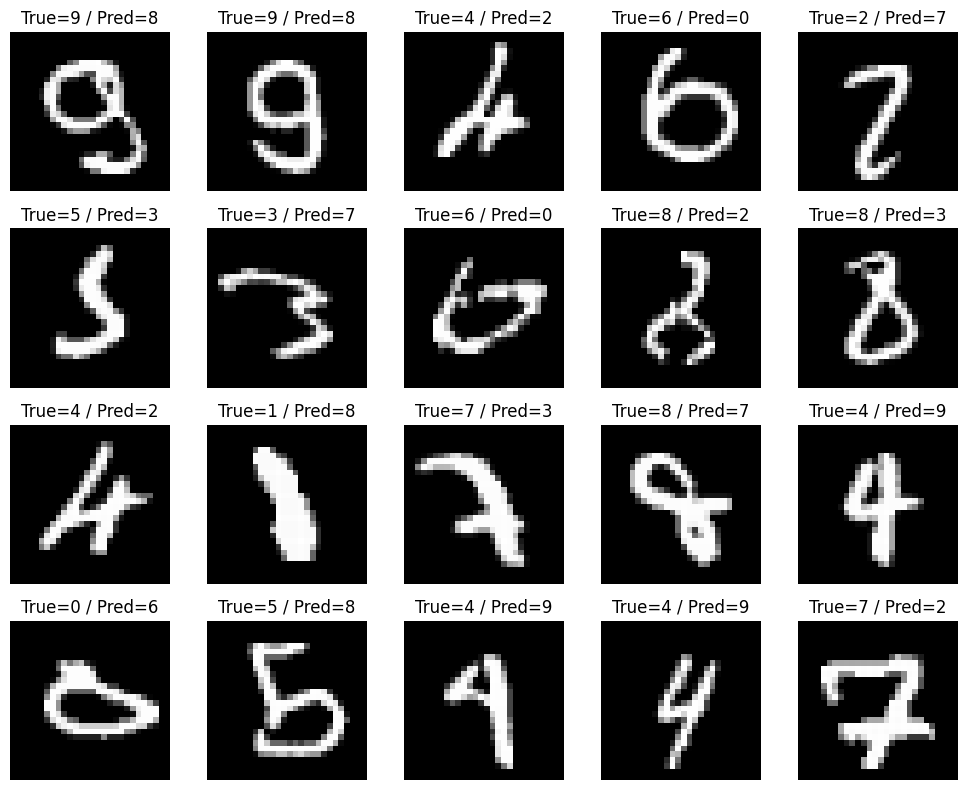

In [ ]:
# EXERCISE SOLUTION
show_n = min(20, len(wrong_indices))

fig, axes = plt.subplots(4, 5, figsize=(10, 8))

for ax, idx in zip(axes.ravel(), wrong_indices[:show_n]):
    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(f"True={y_test[idx]} / Pred={y_pred[idx]}")
    ax.axis("off")

plt.tight_layout()
plt.show()


# 15. Overfitting

A model can memorize the training data while performing worse on unseen data.

Common tools to reduce overfitting include:

- dropout,
- L2 regularization,
- data augmentation,
- early stopping,
- reducing model complexity,
- obtaining more representative training data.

We already used `Dropout(0.20)` in the MLP.


In [ ]:
# Build a deliberately larger MLP so we can practice regularization.
large_mlp = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

large_mlp.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

large_mlp.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

## 15.1 Early stopping

Early stopping monitors validation performance.

If validation loss stops improving, training can stop and the best weights can be restored.

This is useful when the exact optimal number of epochs is unknown.


In [ ]:
# Stop training when validation loss no longer improves.
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train the larger model with early stopping.
early_history = large_mlp.fit(
    X_train_mlp,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.10,
    callbacks=[early_stop],
    verbose=1
)

print("Epochs actually completed:", len(early_history.history["loss"]))


Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9146 - loss: 0.2978 - val_accuracy: 0.9672 - val_loss: 0.1111
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9676 - loss: 0.1060 - val_accuracy: 0.9767 - val_loss: 0.0832
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9780 - loss: 0.0712 - val_accuracy: 0.9773 - val_loss: 0.0756
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9832 - loss: 0.0519 - val_accuracy: 0.9767 - val_loss: 0.0775
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9881 - loss: 0.0384 - val_accuracy: 0.9803 - val_loss: 0.0711
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9915 - loss: 0.0267 - val_accuracy: 0.9770 - val_loss: 0.0846
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9913 - loss: 0.0258 - val_accuracy: 0.9818 - val_loss: 0.0752
Epochs actually completed: 7


# 16. CNN: why convolutions?

An MLP sees a flattened image as a vector of 784 values.

A CNN instead preserves spatial structure:

```text
28 × 28 image
     ↓
Convolution
     ↓
Feature maps
     ↓
Pooling
     ↓
Deeper convolution
     ↓
Flatten / classifier
```

A convolution filter looks at **local neighborhoods**.

This gives CNNs useful properties for images:

- local connectivity,
- parameter sharing,
- hierarchical feature extraction,
- some robustness to small spatial shifts.


## 16.1 Convolution intuition

Imagine a small `3 × 3` filter moving across the image.

At each position it performs a weighted sum of the local pixels.

Different filters can learn to respond to different patterns, such as:

- horizontal edges,
- vertical edges,
- curves,
- corners,
- more complex structures.


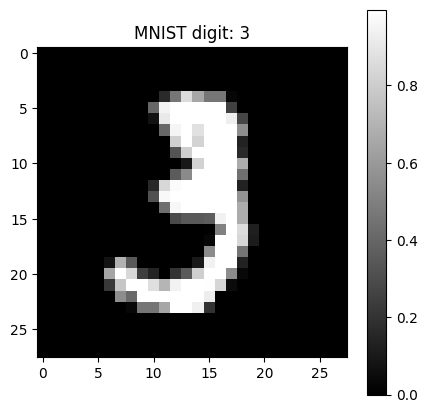

Top-left 5x5 pixel values:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]


In [ ]:
# Visualize a sample image as a numeric 28x28 array.
idx = 10

plt.figure(figsize=(5, 5))
plt.imshow(X_train_norm[idx], cmap="gray")
plt.title(f"MNIST digit: {y_train[idx]}")
plt.colorbar()
plt.show()

# Display a small top-left region numerically.
print("Top-left 5x5 pixel values:")
print(X_train_norm[idx][:5, :5])


# 17. Prepare data for a CNN

A grayscale CNN input uses:

$$
(height, width, channels) = (28, 28, 1)
$$

We add the channel dimension at the end.


In [ ]:
# Add the grayscale channel dimension.
X_train_cnn = X_train_norm[..., np.newaxis]
X_test_cnn = X_test_norm[..., np.newaxis]

print("CNN training shape:", X_train_cnn.shape)
print("CNN test shape:", X_test_cnn.shape)


CNN training shape: (60000, 28, 28, 1)
CNN test shape: (10000, 28, 28, 1)


# 18. Build a CNN with Keras

A compact educational architecture:

```text
28×28×1
  ↓
Conv2D(32, 3×3) + ReLU
  ↓
MaxPooling(2×2)
  ↓
Conv2D(64, 3×3) + ReLU
  ↓
MaxPooling(2×2)
  ↓
Flatten
  ↓
Dense(64) + ReLU
  ↓
Dropout
  ↓
Dense(10) + Softmax
```


In [ ]:
# Build the CNN.
cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Learn local visual patterns such as edges and small shapes.
    layers.Conv2D(32, (3, 3), activation="relu"),

    # Reduce spatial resolution while keeping important responses.
    layers.MaxPooling2D((2, 2)),

    # Learn more complex patterns from the previous feature maps.
    layers.Conv2D(64, (3, 3), activation="relu"),

    # Reduce spatial dimensions again.
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a vector before the dense classifier.
    layers.Flatten(),

    # Combine learned visual features for classification.
    layers.Dense(64, activation="relu"),

    # Regularize the classifier.
    layers.Dropout(0.30),

    # Final ten class probabilities.
    layers.Dense(10, activation="softmax")
])

cnn.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

## 18.1 Inspect trainable parameters

Compare the CNN parameter count with the MLP.

The important idea is not only the number of parameters. The CNN also uses the **spatial arrangement** of pixels and shared convolution filters.


In [ ]:
# Print the total trainable parameter count.
trainable_params = np.sum([
    np.prod(v.shape) for v in cnn.trainable_variables
])

print("Trainable parameters before build:", trainable_params)
print("Use cnn.summary() above for the layer-by-layer breakdown.")


Trainable parameters before build: 121930
Use cnn.summary() above for the layer-by-layer breakdown.


# 19. Compile and train the CNN

For a fair classroom comparison, we use the same MNIST labels and the same categorical loss.


In [ ]:
# Configure the CNN optimizer, loss and metric.
cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train the CNN.
cnn_history = cnn.fit(
    X_train_cnn,
    y_train,
    epochs=6,
    batch_size=128,
    validation_split=0.10,
    verbose=1
)


Epoch 1/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 102ms/step - accuracy: 0.8979 - loss: 0.3378 - val_accuracy: 0.9787 - val_loss: 0.0677
Epoch 2/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9668 - loss: 0.1095 - val_accuracy: 0.9852 - val_loss: 0.0498
Epoch 3/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 103ms/step - accuracy: 0.9759 - loss: 0.0805 - val_accuracy: 0.9877 - val_loss: 0.0451
Epoch 4/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 100ms/step - accuracy: 0.9804 - loss: 0.0655 - val_accuracy: 0.9882 - val_loss: 0.0387
Epoch 5/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9834 - loss: 0.0545 - val_accuracy: 0.9897 - val_loss: 0.0380
Epoch 6/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9856 - loss: 0.0466 - val_accuracy: 0.9905 - val_loss: 0.0355


## 19.1 CNN training curves


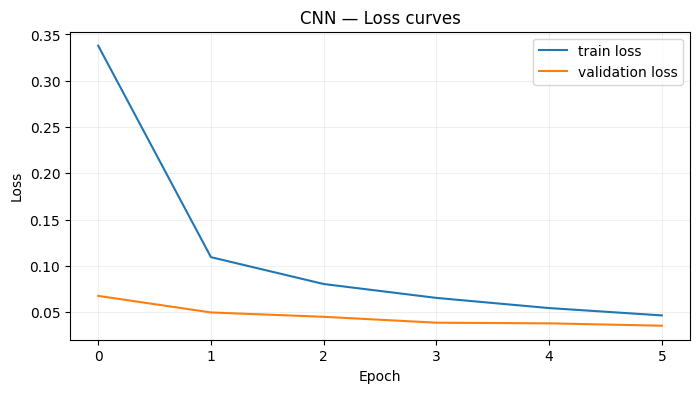

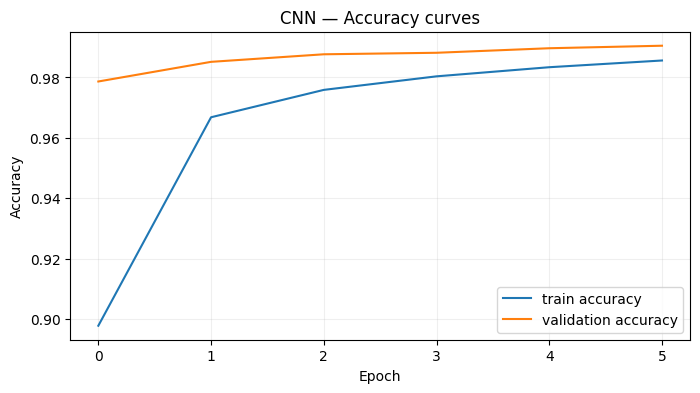

In [ ]:
# Plot CNN loss and accuracy.
cnn_history_df = pd.DataFrame(cnn_history.history)

plt.figure(figsize=(8, 4))
plt.plot(cnn_history_df["loss"], label="train loss")
plt.plot(cnn_history_df["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN — Loss curves")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(cnn_history_df["accuracy"], label="train accuracy")
plt.plot(cnn_history_df["val_accuracy"], label="validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN — Accuracy curves")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# 20. Evaluate the CNN


In [ ]:
# Measure performance on the unseen test set.
cnn_test_loss, cnn_test_accuracy = cnn.evaluate(X_test_cnn, y_test, verbose=0)

print(f"CNN test loss: {cnn_test_loss:.4f}")
print(f"CNN test accuracy: {cnn_test_accuracy:.4f}")


CNN test loss: 0.0326
CNN test accuracy: 0.9880


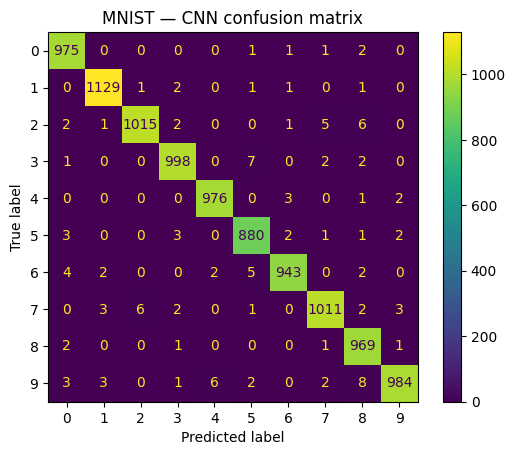

In [ ]:
# Generate CNN predictions for error analysis.
cnn_prob = cnn.predict(X_test_cnn, verbose=0)
cnn_pred = np.argmax(cnn_prob, axis=1)

# Display the CNN confusion matrix.
cnn_cm = confusion_matrix(y_test, cnn_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cnn_cm,
    display_labels=np.arange(10)
)
disp.plot(values_format="d")
plt.title("MNIST — CNN confusion matrix")
plt.show()


# 21. MLP vs CNN

We have now built two different neural approaches for the same image-classification problem.

| Model | Input representation | Main idea |
|---|---|---|
| MLP | `784` flattened pixels | Dense connections |
| CNN | `28×28×1` image | Local convolutional features |

The comparison should be based on measurements from the actual run rather than assuming that one architecture always wins.


In [ ]:
# Compare the measured test results from this notebook.
comparison = pd.DataFrame({
    "Model": ["MLP", "CNN"],
    "Test loss": [test_loss, cnn_test_loss],
    "Test accuracy": [test_accuracy, cnn_test_accuracy]
})

comparison


,Model,Test loss,Test accuracy
0,MLP,0.074331,0.9765
1,CNN,0.032557,0.9880


# 22. Single-image CNN prediction

A production-style inference function should hide preprocessing details.

The input is a raw `28×28` image and the output is a predicted class and probability distribution.


In [ ]:
def predict_digit_cnn(model, image):
    # Convert the image to float values in [0, 1].
    image = image.astype("float32") / 255.0

    # Add the channel dimension: 28x28 -> 28x28x1.
    image = image[..., np.newaxis]

    # Add the batch dimension because Keras expects batches.
    image = image[np.newaxis, ...]

    # Get the ten class probabilities.
    probabilities = model.predict(image, verbose=0)[0]

    # Select the most probable digit.
    predicted_class = int(np.argmax(probabilities))

    return predicted_class, probabilities

# Test the function.
idx = 250
predicted, probabilities = predict_digit_cnn(cnn, X_test[idx])

print("True digit:", int(y_test[idx]))
print("Predicted digit:", predicted)
print("Probabilities:", probabilities)


True digit: 4
Predicted digit: 4
Probabilities: [0.     0.     0.     0.     0.9999 0.     0.     0.     0.     0.0001]


# 23. Exercise — modify the CNN

Create a new CNN and experiment with one architectural change.

Possible experiments:

1. Change the first convolution from 32 to 16 filters.
2. Change the dense layer from 64 to 128 neurons.
3. Change dropout from `0.30` to `0.50`.
4. Add another `Conv2D` layer.
5. Change the batch size.

Record:

- architecture,
- number of parameters,
- training time (qualitatively is sufficient),
- test accuracy,
- your observations.

Do not assume that a more complex model must perform better.


In [ ]:
# EXERCISE STARTER
experiment_cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # TODO: Try changing the number of filters.
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    # TODO: Try changing the number of dense neurons.
    layers.Dense(64, activation="relu"),

    # TODO: Try changing the dropout rate.
    layers.Dropout(0.30),

    layers.Dense(10, activation="softmax")
])

experiment_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

experiment_cnn.summary()

# TODO: Train the model and evaluate it.


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

# 24. Data augmentation

For some image problems, the training images can be transformed in ways that preserve their class.

Examples:

- small rotations,
- translations,
- zoom,
- contrast changes,
- horizontal flips **when a flip makes sense for the domain**.

Augmentation should reflect realistic variations. An unrealistic transformation can make training worse.


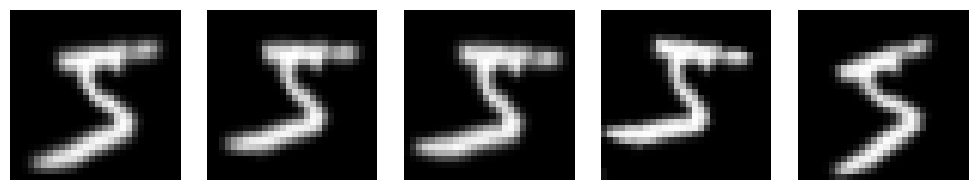

In [ ]:
# A Keras augmentation pipeline.
augmentation = keras.Sequential([
    # Small rotations simulate changes in writing orientation.
    layers.RandomRotation(0.05),

    # Small zoom changes simulate scale variation.
    layers.RandomZoom(0.05),

    # Small translations simulate a digit not being perfectly centered.
    layers.RandomTranslation(0.05, 0.05)
])

# Visualize several augmented versions of one digit.
image = X_train_cnn[0:1]

plt.figure(figsize=(10, 2))

for i in range(5):
    augmented = augmentation(image, training=True)
    plt.subplot(1, 5, i + 1)
    plt.imshow(augmented[0, ..., 0], cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


# 25. Model saving and loading

A trained model should not have to be retrained every time it is used.

Keras supports the `.keras` format.

This is useful for:

- deployment,
- reproducibility,
- sharing a model,
- future inference,
- continuing training later.


In [ ]:
# Save the trained CNN in the native Keras format.
model_path = "mnist_intro_deep_learning_cnn.keras"
cnn.save(model_path)

print("Saved:", model_path)

# Load the model back.
loaded_cnn = keras.models.load_model(model_path)

# Verify that the loaded model can perform inference.
loaded_pred, loaded_probs = predict_digit_cnn(loaded_cnn, X_test[0])

print("Loaded model prediction:", loaded_pred)
print("Original label:", int(y_test[0]))


Saved: mnist_intro_deep_learning_cnn.keras
Loaded model prediction: 7
Original label: 7


# 26. Reproducibility

Results can vary because neural-network training includes random initialization and mini-batch ordering.

For classroom demonstrations, setting random seeds makes experiments more repeatable, although exact reproducibility can still depend on the hardware and software environment.


In [ ]:
# Set common random seeds for more repeatable classroom experiments.
np.random.seed(42)
tf.random.set_seed(42)

print("Random seeds set to 42.")


Random seeds set to 42.


# 27. Deep Learning workflow

A practical workflow is:

```text
Define the problem
       ↓
Collect / inspect data
       ↓
Clean and preprocess
       ↓
Split train / validation / test
       ↓
Choose a baseline
       ↓
Build the neural network
       ↓
Choose loss + optimizer + metrics
       ↓
Train
       ↓
Monitor validation performance
       ↓
Evaluate on test data
       ↓
Inspect errors
       ↓
Save / deploy
```

### Important engineering principle

A high accuracy number is not enough.

Always ask:

- Which classes are difficult?
- What are the false positives and false negatives?
- Is the validation strategy appropriate?
- Is there data leakage?
- Does the test set represent the deployment situation?
- Is the model confident for the right reasons?


# 28. Exercise — build a mini binary classifier

Create a binary MNIST dataset using only digits **0 and 1**.

Your task:

1. Filter the dataset.
2. Build a small MLP.
3. Use one output neuron with a sigmoid activation.
4. Use `binary_crossentropy`.
5. Train the model.
6. Evaluate test accuracy.
7. Display at least five predictions.


In [ ]:
# EXERCISE STARTER — binary classification: 0 vs 1

# Select only examples belonging to classes 0 and 1.
train_mask = np.isin(y_train, [0, 1])
test_mask = np.isin(y_test, [0, 1])

X_bin_train = X_train_norm[train_mask].reshape(-1, 784)
y_bin_train = y_train[train_mask].astype("float32")

X_bin_test = X_test_norm[test_mask].reshape(-1, 784)
y_bin_test = y_test[test_mask].astype("float32")

# TODO: Build an MLP with:
# - Input(784)
# - Dense(32, activation="relu")
# - Dense(1, activation="sigmoid")

binary_mlp = None

# TODO: Compile with:
# - optimizer="adam"
# - loss="binary_crossentropy"
# - metrics=["accuracy"]

# TODO: Train and evaluate the model.


In [ ]:
# EXERCISE SOLUTION — binary classification: 0 vs 1

binary_mlp = keras.Sequential([
    # Receive flattened 28x28 images.
    layers.Input(shape=(784,)),

    # Learn a nonlinear representation.
    layers.Dense(32, activation="relu"),

    # A single sigmoid output represents P(class = 1).
    layers.Dense(1, activation="sigmoid")
])

binary_mlp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

binary_history = binary_mlp.fit(
    X_bin_train,
    y_bin_train,
    epochs=5,
    batch_size=128,
    validation_split=0.10,
    verbose=1
)

binary_loss, binary_accuracy = binary_mlp.evaluate(
    X_bin_test,
    y_bin_test,
    verbose=0
)

print(f"Binary test loss: {binary_loss:.4f}")
print(f"Binary test accuracy: {binary_accuracy:.4f}")


Epoch 1/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9845 - loss: 0.0832 - val_accuracy: 0.9992 - val_loss: 0.0082
Epoch 2/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9984 - loss: 0.0076 - val_accuracy: 0.9992 - val_loss: 0.0035
Epoch 3/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9989 - loss: 0.0048 - val_accuracy: 1.0000 - val_loss: 0.0020
Epoch 4/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9990 - loss: 0.0036 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 5/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9994 - loss: 0.0029 - val_accuracy: 1.0000 - val_loss: 0.0010
Binary test loss: 0.0021
Binary test accuracy: 0.9995


# 29. Exercise — understand the output layer

Complete the table conceptually:

| Problem | Output layer | Typical loss |
|---|---|---|
| Binary classification | `Dense(1, sigmoid)` | Binary cross-entropy |
| Multiclass, integer labels | `Dense(K, softmax)` | Sparse categorical cross-entropy |
| Multiclass, one-hot labels | `Dense(K, softmax)` | Categorical cross-entropy |

Then explain why using `Dense(10, softmax)` is appropriate for MNIST.


# 30. Final practical exercise — improve the classifier

Start from the CNN and create an improved version.

Choose at least **two** changes:

- data augmentation,
- dropout,
- a different learning rate,
- an additional convolutional layer,
- batch normalization,
- a different number of filters,
- early stopping.

### Deliverable

Report:

1. final architecture,
2. number of epochs,
3. test accuracy,
4. confusion matrix,
5. two examples of errors,
6. one limitation of your model.


In [ ]:
# FINAL EXERCISE STARTER
# Build your improved CNN here.
# Keep comments explaining every architectural choice.

improved_cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # TODO: Add your layers here.
    # Example:
    # layers.Conv2D(32, (3, 3), activation="relu"),
    # layers.MaxPooling2D((2, 2)),

    # TODO: Complete the classifier.
])

# TODO: Compile the model.
# TODO: Train the model.
# TODO: Evaluate it.
# TODO: Plot a confusion matrix.


Epoch 1/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 103ms/step - accuracy: 0.9181 - loss: 0.2740 - val_accuracy: 0.9832 - val_loss: 0.0591
Epoch 2/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 105ms/step - accuracy: 0.9741 - loss: 0.0848 - val_accuracy: 0.9878 - val_loss: 0.0444
Epoch 3/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 102ms/step - accuracy: 0.9812 - loss: 0.0613 - val_accuracy: 0.9903 - val_loss: 0.0341
Epoch 4/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 102ms/step - accuracy: 0.9838 - loss: 0.0513 - val_accuracy: 0.9902 - val_loss: 0.0339
Epoch 5/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 102ms/step - accuracy: 0.9867 - loss: 0.0409 - val_accuracy: 0.9912 - val_loss: 0.0314
Epoch 6/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 102ms/step - accuracy: 0.9884 - loss: 0.0366 - val_accuracy: 0.9898 - val_loss: 0.0337
Final test loss: 0.0270
Final test accuracy: 0.9919


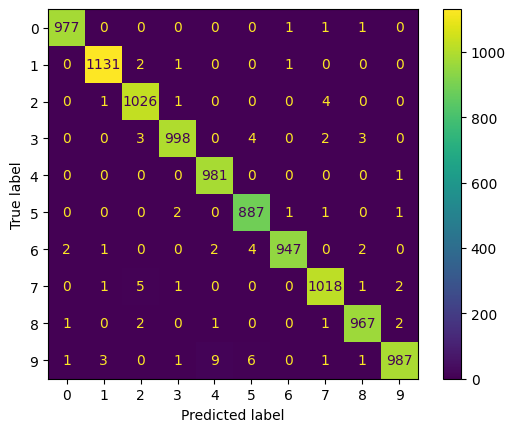

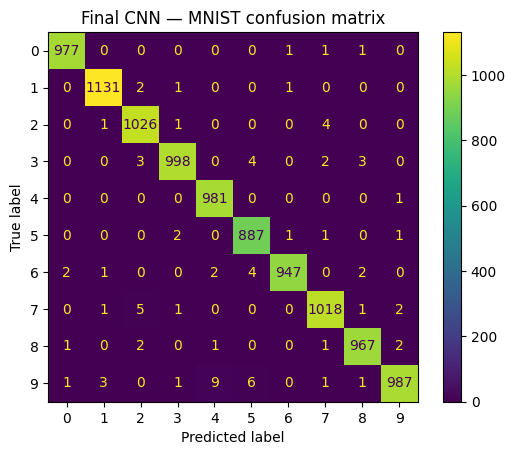

In [ ]:
# One possible solution to the final exercise.
# Treat this as a reference implementation, then create your own variant.

improved_cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Learn low-level local patterns.
    layers.Conv2D(32, (3, 3), activation="relu"),

    # Reduce spatial dimensions.
    layers.MaxPooling2D((2, 2)),

    # Learn more complex patterns.
    layers.Conv2D(64, (3, 3), activation="relu"),

    # Reduce the feature-map size again.
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a vector.
    layers.Flatten(),

    # Nonlinear classifier.
    layers.Dense(128, activation="relu"),

    # Reduce over-reliance on individual neurons.
    layers.Dropout(0.40),

    # Ten output classes with probabilities.
    layers.Dense(10, activation="softmax")
])

improved_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

final_history = improved_cnn.fit(
    X_train_cnn,
    y_train,
    epochs=6,
    batch_size=128,
    validation_split=0.10,
    verbose=1
)

final_loss, final_accuracy = improved_cnn.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print(f"Final test loss: {final_loss:.4f}")
print(f"Final test accuracy: {final_accuracy:.4f}")

# Generate predictions for the confusion matrix.
final_prob = improved_cnn.predict(X_test_cnn, verbose=0)
final_pred = np.argmax(final_prob, axis=1)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_pred,
    display_labels=np.arange(10)
)
disp.plot(values_format="d")
plt.title("Final CNN — MNIST confusion matrix")
plt.show()


# 31. Quick reference

## Core concepts

```text
Neuron       = weighted sum + bias + activation
Layer        = collection of neurons
Forward pass = compute prediction
Loss         = measure error
Gradient     = direction of loss change
Backprop      = compute gradients efficiently
Optimizer    = update parameters
Epoch         = one pass through training data
Batch         = subset used for one update
Overfitting  = training improves while generalization degrades
```

## Common Keras components

```python
layers.Dense(...)
layers.Conv2D(...)
layers.MaxPooling2D(...)
layers.Dropout(...)
keras.optimizers.Adam(...)
keras.callbacks.EarlyStopping(...)
```

## Typical classification outputs

```python
# Binary classification
layers.Dense(1, activation="sigmoid")

# Multiclass classification
layers.Dense(number_of_classes, activation="softmax")
```


# 32. Final checklist

Before considering a deep-learning experiment complete, verify:

- [ ] The problem and target are clearly defined.
- [ ] Training / validation / test data are separated appropriately.
- [ ] Inputs are preprocessed consistently.
- [ ] The output layer matches the task.
- [ ] The loss function matches the labels.
- [ ] The optimizer and learning rate are recorded.
- [ ] Training and validation curves were inspected.
- [ ] Test performance was measured only after model selection.
- [ ] A confusion matrix or other appropriate error analysis was performed.
- [ ] The model and preprocessing steps can be reproduced.


# 33. Mini-project ideas

### A. Traffic Sign Recognition
Build a CNN for traffic-sign images and analyze the most confused signs.

### B. Industrial Defect Detection
Train an image classifier to identify normal vs defective components.

### C. Handwritten Character Recognition
Move from MNIST digits to another alphabet or character dataset.

### D. Medical Image Classification
Use a suitable public dataset and pay special attention to class imbalance, leakage, calibration and clinically meaningful error analysis.

### E. Transfer Learning
Replace the small MNIST CNN with a pretrained vision model and compare the training strategy.

For a real engineering project, document the dataset, preprocessing, architecture, hyperparameters, evaluation protocol and limitations.


# Conclusion

You have followed a complete introductory Deep Learning workflow:

**neuron → activation → forward propagation → loss → gradient descent → backpropagation → neural network → MLP → CNN → evaluation → deployment-ready saving**

The most important idea is:

> Deep learning is not simply "using more layers". It is learning useful representations and parameters from data through optimization.

Continue by changing the notebook parameters, testing new architectures, and carefully analyzing the resulting errors.
